# Monetary stability in Armenia

This project studies inflation and exchange rate dynamics in Armenia.

The goal is to see whether the economy became more stable over time.

## Theory

Monetary stability is important for an economy.


Inflation shows internal stability. High inflation means instability.
The exchange rate shows external stability. Large variations suggest a weak currency.

This project uses a simple time series approach based on correlation and rolling statistics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def clean_data(file, value_name):
    """Clean and prepare World Bank data"""
    df = pd.read_csv(file, skiprows=4)
    df = df[df["Country Name"] == "Armenia"]

    df = df.melt(
        id_vars=["Country Name"],
        var_name="Year",
        value_name=value_name
    )

    df = df[df["Year"].str.isnumeric()]
    df["Year"] = df["Year"].astype(int)
    df[value_name] = pd.to_numeric(df[value_name], errors="coerce")

    df = df.dropna()
    df = df.sort_values("Year").reset_index(drop=True)

    return df[["Year", value_name]]

In [3]:
class MonetaryPolicyAnalysis:
    """Simple analysis of inflation and exchange rate"""

    def __init__(self, data):
        self.data = data

    def select(self, start=None):
        """Return the data, optionally restricted to years >= start"""
        if start is None:
            return self.data
        return self.data.loc[start:]

    def summary(self, start=None):
        """Descriptive statistics of inflation and depreciation"""
        return self.select(start)[["Inflation", "Depreciation"]].describe()

    def correlation(self, start=None):
        """Correlation between inflation and the rate of depreciation

        Both variables must be rates of change. The exchange rate level
        is a trending series and cannot be compared with an inflation rate.
        """
        return self.select(start)[["Inflation", "Depreciation"]].corr()

    def volatility(self, window=5):
        """Rolling standard deviation

        This measures how stable the variables are, which is not the
        same thing as how high they are.
        """
        return self.data[["Inflation", "Depreciation"]].rolling(window).std()

## Data

World Bank data for Armenia:
- inflation
- exchange rate

In [4]:
inflation = clean_data("inflation.csv", "Inflation")
exchange = clean_data("exchange.csv", "Exchange_Rate")

In [5]:
inflation.head()

,Year,Inflation
0,1994,3373.759443
1,1995,175.951326
2,1996,18.681186
3,1997,13.960764
4,1998,8.672486


## Inflation

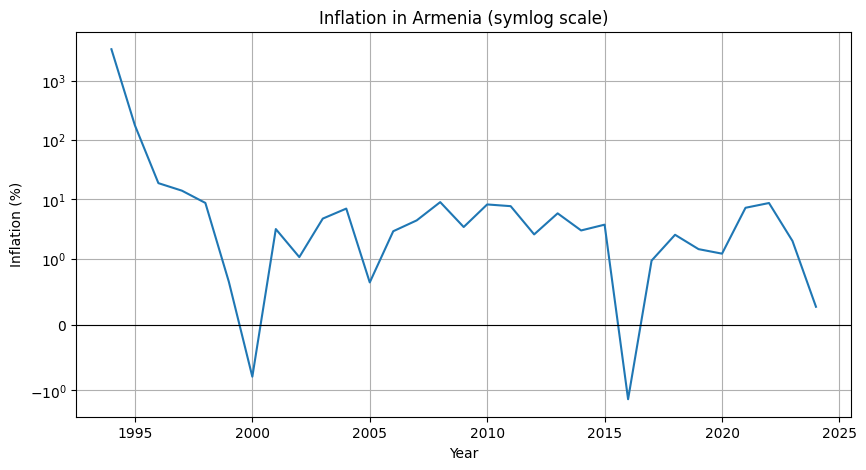

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(inflation["Year"], inflation["Inflation"])
plt.yscale("symlog", linthresh=1)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Inflation in Armenia (symlog scale)")
plt.xlabel("Year")
plt.ylabel("Inflation (%)")
plt.grid()
plt.show()

Inflation was very high in the 1990s.
Then it became more stable.

The vertical axis uses a symlog scale. A linear scale is unusable here: the 1994
value of 3374% flattens every other year into a straight line at zero. But a plain
log scale cannot be used either, because it has no room for zero or negative
values, and Armenia had deflation in 2000 (-0.8%) and 2016 (-1.4%). A log scale
would drop those two years silently.

Symlog is linear between -1 and +1 and logarithmic beyond. The horizontal line
marks zero, so deflation years stay visible below it.

This suggests an improvement in internal stability.
This period corresponds to the economic transition after independence.

## Exchange rate

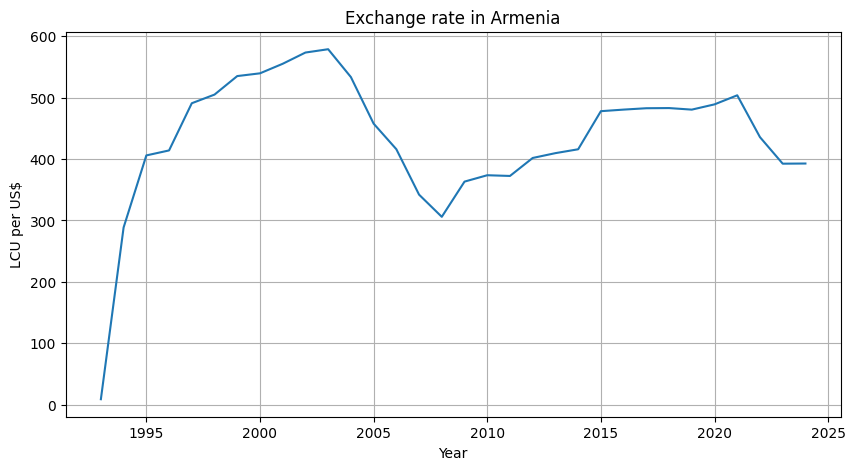

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(exchange["Year"], exchange["Exchange_Rate"])
plt.title("Exchange rate in Armenia")
plt.xlabel("Year")
plt.ylabel("LCU per US$")
plt.grid()
plt.show()

The exchange rate increased over time.

Large variations in the early period suggest instability.
Later, changes are smaller, indicating more stability.

This reflects a gradual stabilization of the currency.

## Merge

In [8]:
df = inflation.merge(exchange, on="Year")
df.head()

,Year,Inflation,Exchange_Rate
0,1994,3373.759443,288.650833
1,1995,175.951326,405.908333
2,1996,18.681186,414.041500
3,1997,13.960764,490.846786
4,1998,8.672486,504.915000


## Time series

In [9]:
df = df.set_index("Year")
df = df.sort_index()

# A rise in drams per dollar is a depreciation of the dram.
# Expressed as a rate, so it can be compared with the inflation rate.
df["Depreciation"] = df["Exchange_Rate"].pct_change() * 100

df.head()

,Inflation,Exchange_Rate,Depreciation
Year,,,
1994,3373.759443,288.650833,NaN
1995,175.951326,405.908333,40.622609
1996,18.681186,414.041500,2.003695
1997,13.960764,490.846786,18.550142
1998,8.672486,504.915000,2.866111


In [10]:
analysis = MonetaryPolicyAnalysis(df)

## Summary statistics

In [11]:
analysis.summary()

,Inflation,Depreciation
count,31.000000,30.000000
mean,118.734532,1.599986
std,604.905785,11.299600
min,-1.403608,-17.777422
25%,1.327441,-0.472440
50%,3.406767,1.240020
75%,7.913185,2.984540
max,3373.759443,40.622609


The data show large variations at the beginning of the period.
This is consistent with a transition phase.

But these statistics cannot be interpreted. A mean inflation of 119% with a
standard deviation of 605% describes no year in the sample. Both numbers are
produced by 1994 alone.

The statistics are therefore computed again from 1996, the first year
inflation falls below 20%.

In [12]:
analysis.summary(start=1996)

,Inflation,Depreciation
count,29.000000,29.000000
mean,4.519301,0.254378
std,4.475632,8.716720
min,-1.403608,-17.777422
25%,1.211436,-0.526476
50%,3.145905,0.943506
75%,7.184836,2.882610
max,18.681186,18.731901


## Correlation

In [13]:
analysis.correlation()

,Inflation,Depreciation
Inflation,1.000000,0.656369
Depreciation,0.656369,1.000000


This correlation uses the depreciation rate, not the exchange rate level.

The level is a trending series: it rises from 289 to 579 drams per dollar over
the period. An inflation rate cannot be compared with a trending level, because
any two series with opposite trends correlate mechanically, whatever the economics.

Both variables therefore have to be expressed as rates of change.

The sign is positive, which is the expected direction. Armenia imports heavily,
so a weaker dram raises domestic prices.

Correlation still does not imply causality.

In [14]:
analysis.correlation(start=1996)

,Inflation,Depreciation
Inflation,1.000000,0.099188
Depreciation,0.099188,1.000000


Restricted to 1996 onwards, the correlation almost disappears.

The positive correlation on the full sample is produced by 1994 and 1995, when
both variables were extreme. After stabilisation, annual data no longer show a
relationship. Annual averages are probably too coarse: exchange rate pass-through
works over months, not years.

## Moving average

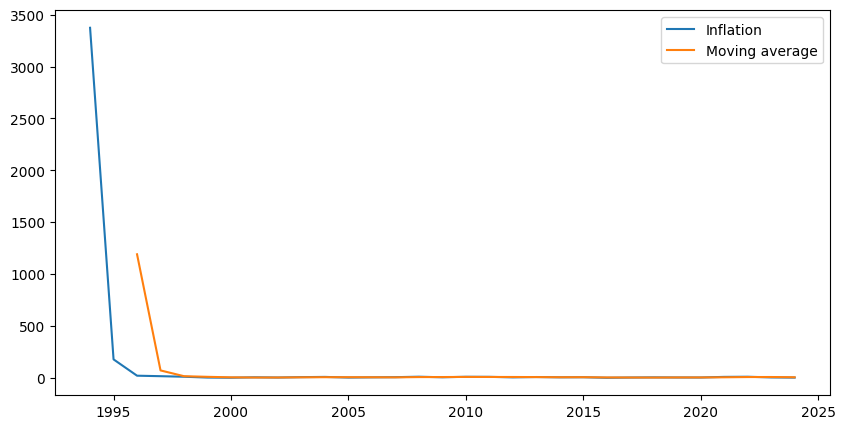

In [15]:
df["Inflation_MA"] = df["Inflation"].rolling(3).mean()

plt.figure(figsize=(10, 5))
plt.plot(df.index, df["Inflation"], label="Inflation")
plt.plot(df.index, df["Inflation_MA"], label="Moving average")
plt.legend()
plt.show()

The moving average shows the long-term trend.

Inflation becomes more stable over time.

This confirms the transition from instability to stability.

## Change in exchange rate

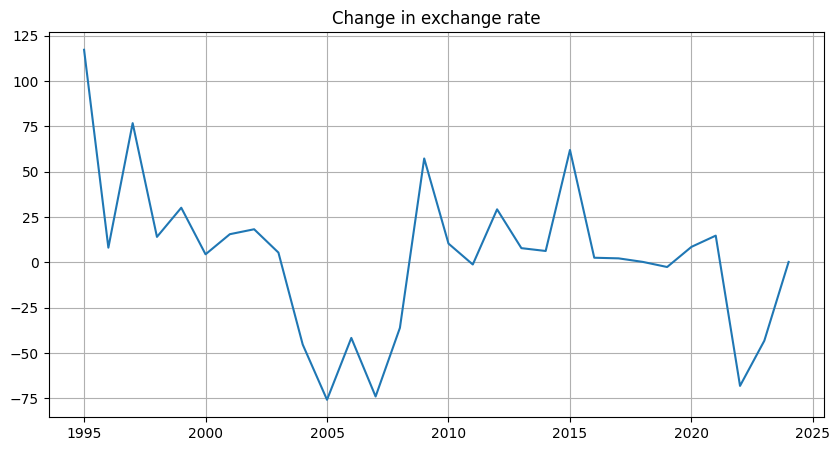

In [16]:
df["Exchange_Change"] = df["Exchange_Rate"].diff()

plt.figure(figsize=(10, 5))
plt.plot(df.index, df["Exchange_Change"])
plt.title("Change in exchange rate")
plt.grid()
plt.show()

Large changes are mostly at the beginning.

Later periods are more stable.

This suggests a reduction in exchange rate volatility.

## Volatility

The moving average above shows the level of inflation, not its stability.
To know whether the economy became more stable, the variation has to be measured.

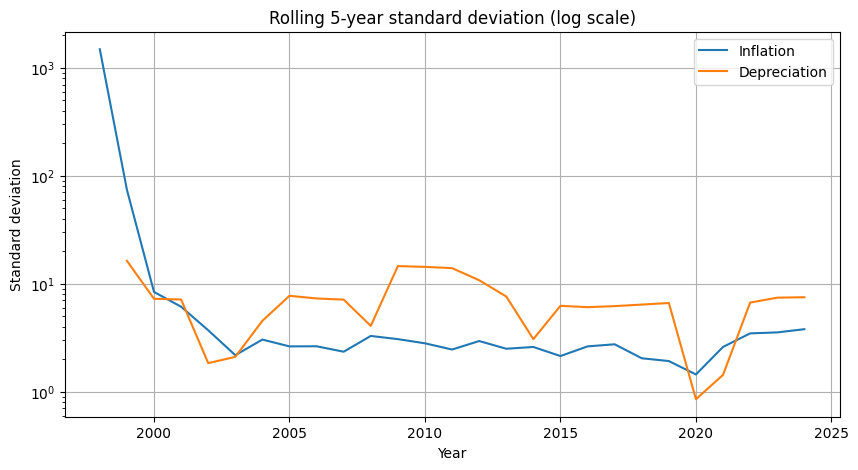

In [17]:
vol = analysis.volatility(window=5)

plt.figure(figsize=(10, 5))
plt.plot(vol.index, vol["Inflation"], label="Inflation")
plt.plot(vol.index, vol["Depreciation"], label="Depreciation")
plt.yscale("log")
plt.title("Rolling 5-year standard deviation (log scale)")
plt.xlabel("Year")
plt.ylabel("Standard deviation")
plt.legend()
plt.grid()
plt.show()

In [18]:
# Average volatility by period, to read the figure as numbers.
periods = [(1996, 1999), (2000, 2009), (2010, 2019), (2020, 2024)]
table = []
for start, end in periods:
    window = vol.loc[start:end]
    table.append({"Period": str(start) + "-" + str(end),
                  "Inflation": window["Inflation"].mean(),
                  "Depreciation": window["Depreciation"].mean()})

table = pd.DataFrame(table).set_index("Period").round(2)
table

,Inflation,Depreciation
Period,,
1996-1999,780.23,16.29
2000-2009,3.73,6.36
2010-2019,2.47,8.12
2020-2024,2.96,4.77


Inflation volatility falls from the hundreds to about 3, and stays there.

Depreciation volatility falls from about 16 to about 6, then rises again to
about 8 in the 2010s before falling in the 2020s. It does not follow the same path.

Internal stability was achieved. External stability was not, in the same sense.

In [19]:
# Export of an external file, as required by the project guidelines.
table.to_csv("volatility_by_period.csv")
print("volatility_by_period.csv written")

volatility_by_period.csv written


## Conclusion

This project studies inflation and exchange rate in Armenia between 1994 and 2024.

Internal stability improved and held. Inflation fell from hyperinflation to single
digits, and its volatility fell by two orders of magnitude and never came back.

External stability did not improve in the same way. The volatility of the
depreciation rate fell much less, and it is not a steady decline: it rises again
in the 2010s. The dram still moves with external conditions.

So the two forms of stability are not the same story. This matters because every
post-Soviet economy disinflated after the 1990s, so the fall in inflation alone
says little that is specific to Armenia.

The link between the two is not established here. The correlation between
depreciation and inflation is clear only in the hyperinflation years. With 31
annual observations and no identification strategy, this project cannot say
whether that reflects a genuinely weak pass-through or simply the limits of the
data.

A proper study would need monthly or quarterly data, an identified monetary
policy shock, and a comparison group such as Georgia or Moldova.